# HbA1c measurement and 30-day readmission
Causal analysis with heterogeneous treatment effects.

Mayank Futnani Arupula · Mentor: Sisi Shao · Student 360 RSP 2026 Summer III

Runs top to bottom. Fixed seed. Asserts verify the cohort before modelling.

**Version 5 (2 November 2026).** Same analysis as v4. Changes: the joint test across diagnosis groups is now a joint Wald test of equality (section 12); the calibration-slope interval uses HC3 robust standard errors (section 11); `np.trapz` is replaced so the notebook runs on NumPy 2.4 and later; package versions are printed at the end (section 16). The submitted manuscript (v11) is unchanged.


## 1. Setup and raw data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# np.trapz was removed in NumPy 2.4; np.trapezoid computes the same trapezoidal rule.
trapz = getattr(np, 'trapezoid', None) or np.trapz

SEED = 20260828
np.random.seed(SEED)

# keep_default_na=False preserves the literal string "None" in A1Cresult
# as a clinical category rather than a missing value.
df = pd.read_csv('diabetic_data.csv', keep_default_na=False)

print("rows:", len(df), " unique patients:", df['patient_nbr'].nunique())
print(df['A1Cresult'].value_counts())

rows: 101766  unique patients: 71518
A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


## 2. Treatment definition with assertions

In [2]:
TESTED = ['Norm', '>7', '>8']
vc = df['A1Cresult'].value_counts()

assert set(vc.index) == {'None','Norm','>7','>8'}, vc.index.tolist()
assert df['A1Cresult'].isna().sum() == 0, "literal None not preserved"

df['A_enc'] = df['A1Cresult'].isin(TESTED).astype(int)
assert df.loc[df.A_enc==0,'A1Cresult'].eq('None').all()
assert df.loc[df.A_enc==1,'A1Cresult'].isin(TESTED).all()
assert df['A_enc'].sum() == vc[TESTED].sum()

print("all encounters -> A=1:", df['A_enc'].sum(), " A=0:", (df['A_enc']==0).sum())

all encounters -> A=1: 17018  A=0: 84748


## 3. Diagnosis grouping

In [3]:
def dxgroup(c):
    if c in ('?', '', None): return 'Missing'
    s = str(c)
    if s.startswith('V') or s.startswith('E'): return 'Other'
    try: v = float(s)
    except: return 'Other'
    if 390 <= v <= 459 or v == 785: return 'Circulatory'
    if 460 <= v <= 519 or v == 786: return 'Respiratory'
    if 520 <= v <= 579 or v == 787: return 'Digestive'
    if int(v) == 250: return 'Diabetes'
    if 800 <= v <= 999: return 'Injury'
    if 710 <= v <= 739: return 'Musculoskeletal'
    if 580 <= v <= 629 or v == 788: return 'Genitourinary'
    if 140 <= v <= 239: return 'Neoplasms'
    return 'Other'

print("defined")

defined


## 4. Cohort construction

Primary rule (Order A): exclude death and hospice discharges first, then take the
earliest remaining encounter per patient by `encounter_id`. This retains every
patient who had at least one encounter with a meaningful opportunity for 30-day
readmission.

In [4]:
BAD = [11, 13, 14, 19, 20, 21]   # expired / hospice discharge codes

d = (df.sort_values('encounter_id')
       .loc[lambda t: ~t['discharge_disposition_id'].isin(BAD)]
       .drop_duplicates('patient_nbr', keep='first')
       .reset_index(drop=True))

d['A'] = d['A1Cresult'].isin(TESTED).astype(int)
d['Y'] = (d['readmitted'] == '<30').astype(int)
d['diag_group'] = d['diag_1'].apply(dxgroup)

assert len(d) == 69990, len(d)
assert d['A'].sum() == 12846, d['A'].sum()
assert d['Y'].sum() == 6285, d['Y'].sum()

print("cohort:", len(d))
print("tested:", d['A'].sum(), f"({d['A'].mean()*100:.2f}%)")
print("readmit <30d:", d['Y'].sum(), f"({d['Y'].mean()*100:.2f}%)")
print("\nunadjusted risk  tested: %.2f%%   untested: %.2f%%" %
      (d.loc[d.A==1,'Y'].mean()*100, d.loc[d.A==0,'Y'].mean()*100))

cohort: 69990
tested: 12846 (18.35%)
readmit <30d: 6285 (8.98%)

unadjusted risk  tested: 8.40%   untested: 9.11%


## 5. Operation-order comparison and 17-patient audit

In [5]:
srt = df.sort_values('encounter_id')

# Order A: exclude, then first surviving encounter
a = (srt.loc[lambda t: ~t['discharge_disposition_id'].isin(BAD)]
        .drop_duplicates('patient_nbr', keep='first'))

# Order B: first encounter, then exclude
b = (srt.drop_duplicates('patient_nbr', keep='first')
        .loc[lambda t: ~t['discharge_disposition_id'].isin(BAD)])

only_a = set(a['patient_nbr']) - set(b['patient_nbr'])
only_b = set(b['patient_nbr']) - set(a['patient_nbr'])

print("Order A (exclude then first):", len(a))
print("Order B (first then exclude):", len(b))
print("in A not B:", len(only_a), "   in B not A:", len(only_b))

chk = srt[srt['patient_nbr'].isin(only_a)].drop_duplicates('patient_nbr', keep='first')
print("\ndischarge code on first encounter, for the", len(only_a), "differing patients:")
print(chk['discharge_disposition_id'].value_counts().to_string())
print("all were death/hospice:", chk['discharge_disposition_id'].isin(BAD).all())

Order A (exclude then first): 69990
Order B (first then exclude): 69973
in A not B: 17    in B not A: 0

discharge code on first encounter, for the 17 differing patients:
discharge_disposition_id
13    7
14    5
11    5
all were death/hospice: True


In [6]:
flow = pd.DataFrame([
    ['Raw encounters', len(df)],
    ['Unique patients', df['patient_nbr'].nunique()],
    ['Order A: exclude then first (PRIMARY)', len(a)],
    ['Order B: first then exclude', len(b)],
    ['Strack et al. reported', 69984],
], columns=['Step','N'])
flow.to_csv('cohort_flow_v2.csv', index=False)
print(flow.to_string(index=False))

                                 Step      N
                       Raw encounters 101766
                      Unique patients  71518
Order A: exclude then first (PRIMARY)  69990
          Order B: first then exclude  69973
               Strack et al. reported  69984


## 6. Covariate set

Primary adjustment set contains only variables plausibly known before treatment.
Excluded per mentor instruction: `number_diagnoses`, `max_glu_serum`, `payer_code`.
Also excluded: `medical_specialty` (baseline status not verifiable, ~48% missing).

`diag_group` (from `diag_1`) is **excluded from the primary adjustment set**. The
primary diagnosis is coded for the encounter and is often finalised at discharge,
so it may carry information recorded after treatment. No documentation establishes
that it was available before HbA1c testing. The specification that adjusts for
diagnosis group is retained as sensitivity analysis S4.

Diagnosis group is still used to *define* subgroups in section 12: effects are
estimated within groups, not adjusted for the group.

Post-treatment variables are excluded throughout.


In [7]:
# PRIMARY: diag_group excluded (see markdown above)
CAT = ['race','gender','age','admission_type_id','admission_source_id']
NUM = ['number_inpatient','number_outpatient','number_emergency']

X = pd.get_dummies(d[CAT].astype(str), drop_first=True)
X = pd.concat([X, d[NUM]], axis=1).astype(float)
Xv = X.values
A = d['A'].values
Y = d['Y'].values
groups = d['patient_nbr'].values

# S4 design matrix: same set plus diagnosis group (sensitivity only)
CAT_S4 = CAT + ['diag_group']
X_s4 = pd.get_dummies(d[CAT_S4].astype(str), drop_first=True)
X_s4 = pd.concat([X_s4, d[NUM]], axis=1).astype(float)

assert X.shape[0] == 69990, X.shape
assert not any('diag_group' in c for c in X.columns), "diag_group leaked into primary X"
print("primary design matrix:", X.shape)
print("S4 design matrix     :", X_s4.shape)


primary design matrix: (69990, 42)
S4 design matrix     : (69990, 51)


In [8]:
rows = [
 ('age','Demographic','Pre-treatment','Fixed at admission','Included'),
 ('race','Demographic','Pre-treatment','Fixed at admission','Included'),
 ('gender','Demographic','Pre-treatment','Fixed at admission','Included'),
 ('admission_type_id','Baseline severity','Pre-treatment','Recorded at admission','Included'),
 ('admission_source_id','Baseline severity','Pre-treatment','Recorded at admission','Included'),
 ('diag_group','Ambiguous','Uncertain','diag_1 may be finalised at discharge; sensitivity S4','Excluded'),
 ('number_inpatient','Prior utilization','Pre-treatment','Prior-year count','Included'),
 ('number_outpatient','Prior utilization','Pre-treatment','Prior-year count','Included'),
 ('number_emergency','Prior utilization','Pre-treatment','Prior-year count','Included'),
 ('number_diagnoses','Ambiguous','Uncertain','Excluded per mentor instruction','Excluded'),
 ('max_glu_serum','Ambiguous','Uncertain','Excluded per mentor instruction','Excluded'),
 ('payer_code','Ambiguous','Uncertain','Excluded per mentor instruction','Excluded'),
 ('medical_specialty','Ambiguous','Uncertain','Baseline status not verifiable; ~48% missing','Excluded'),
 ('change','In-hospital care','Post-treatment','Mediator on A -> M -> Y','Excluded'),
 ('time_in_hospital','In-hospital care','Post-treatment','Realized after admission','Excluded'),
 ('num_lab_procedures','In-hospital care','Post-treatment','Counts the HbA1c test itself','Excluded'),
 ('num_medications','In-hospital care','Post-treatment','In-hospital treatment','Excluded'),
 ('num_procedures','In-hospital care','Post-treatment','In-hospital treatment','Excluded'),
 ('discharge_disposition_id','Discharge','Post-treatment','Cohort exclusion only','Excluded'),
 ('A1Cresult value','Treatment detail','Post-treatment','Exists only if tested','Excluded'),
 ('diabetesMed','In-hospital care','Post-treatment','Medication status during stay','Excluded'),
]
ct = pd.DataFrame(rows, columns=['Variable','Domain','Timing','Rationale','Primary set'])
ct.to_csv('covariate_timing_table_v2.csv', index=False)
print(ct.to_string(index=False))

                Variable            Domain         Timing                                            Rationale Primary set
                     age       Demographic  Pre-treatment                                   Fixed at admission    Included
                    race       Demographic  Pre-treatment                                   Fixed at admission    Included
                  gender       Demographic  Pre-treatment                                   Fixed at admission    Included
       admission_type_id Baseline severity  Pre-treatment                                Recorded at admission    Included
     admission_source_id Baseline severity  Pre-treatment                                Recorded at admission    Included
              diag_group         Ambiguous      Uncertain diag_1 may be finalised at discharge; sensitivity S4    Excluded
        number_inpatient Prior utilization  Pre-treatment                                     Prior-year count    Included
       number_ou

## 7. Nuisance models with five-fold cross-fitting

All encounters from the same patient stay in the same fold. Predictions are
generated out of fold.

In [9]:
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

gkf = GroupKFold(n_splits=5)
e_hat = np.zeros(len(d)); mu0 = np.zeros(len(d)); mu1 = np.zeros(len(d))

for tr, te in gkf.split(Xv, A, groups=groups):
    ps = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    ps.fit(Xv[tr], A[tr])
    e_hat[te] = ps.predict_proba(Xv[te])[:, 1]
    for aval, mu in [(0, mu0), (1, mu1)]:
        m = tr[A[tr] == aval]
        gb = GradientBoostingClassifier(n_estimators=200, max_depth=3,
                learning_rate=0.05, subsample=0.8, random_state=SEED)
        gb.fit(Xv[m], Y[m])
        mu[te] = gb.predict_proba(Xv[te])[:, 1]

print("PS range:", round(e_hat.min(), 4), round(e_hat.max(), 4))

PS range: 0.0 1.0


### Trimming rule and propensity tails

In [10]:
EPS = 0.01
print("PS < 0.01:", (e_hat < EPS).sum())
print("PS > 0.99:", (e_hat > 1-EPS).sum())
print("PS < 0.05:", (e_hat < 0.05).sum(), "  PS > 0.95:", (e_hat > 0.95).sum())

e_clip = np.clip(e_hat, EPS, 1-EPS)
print("\nRule: clip to [0.01, 0.99]. No observations dropped.")
print("clipped:", ((e_hat < EPS) | (e_hat > 1-EPS)).sum())

PS < 0.01: 4
PS > 0.99: 1
PS < 0.05: 1098   PS > 0.95: 1

Rule: clip to [0.01, 0.99]. No observations dropped.
clipped: 5


## 8. Average treatment effect

Confidence interval from the standard deviation of the estimated influence
function divided by sqrt(n), normal approximation.

In [11]:
crude = Y[A==1].mean() - Y[A==0].mean()
gcomp = (mu1 - mu0).mean()

w1 = A/e_clip; w0 = (1-A)/(1-e_clip)
ipw = (w1*Y).sum()/w1.sum() - (w0*Y).sum()/w0.sum()

psi = (mu1-mu0) + A*(Y-mu1)/e_clip - (1-A)*(Y-mu0)/(1-e_clip)
aipw = psi.mean()
se_ate = psi.std(ddof=1)/np.sqrt(len(psi))
ci_lo, ci_hi = aipw - 1.96*se_ate, aipw + 1.96*se_ate

for nm, v in [('Crude', crude), ('G-computation', gcomp), ('IPW (stabilized)', ipw)]:
    print(f"{nm:22s} {v*100:7.3f}")
print(f"{'AIPW (primary)':22s} {aipw*100:7.3f}   95% CI {ci_lo*100:.3f} to {ci_hi*100:.3f}")

pd.DataFrame([
    ['Crude', round(crude*100,3), None, None],
    ['Outcome regression', round(gcomp*100,3), None, None],
    ['IPW (stabilized)', round(ipw*100,3), None, None],
    ['AIPW', round(aipw*100,3), round(ci_lo*100,3), round(ci_hi*100,3)],
], columns=['Estimator','RD_pp','CI_low','CI_high']).to_csv('ate_estimates_v2.csv', index=False)

Crude                   -0.711
G-computation           -0.134
IPW (stabilized)         0.013
AIPW (primary)          -0.082   95% CI -0.696 to 0.532


### Master table

In [12]:
# AIPW arm-specific marginal risks. By construction psi1 - psi0 == psi,
# so these two risks differ by exactly the reported AIPW risk difference.
psi1 = mu1 + A*(Y-mu1)/e_clip
psi0 = mu0 + (1-A)*(Y-mu0)/(1-e_clip)
r1, r0 = psi1.mean(), psi0.mean()
se1 = psi1.std(ddof=1)/np.sqrt(len(psi1))
se0 = psi0.std(ddof=1)/np.sqrt(len(psi0))
assert abs((r1 - r0) - aipw) < 1e-10, "arm risks do not reconcile with the AIPW RD"

master = pd.DataFrame([
    ['N', int((A==1).sum()), int((A==0).sum())],
    ['Outcome events', int(Y[A==1].sum()), int(Y[A==0].sum())],
    ['Unadjusted 30-day risk (%)', round(Y[A==1].mean()*100,3), round(Y[A==0].mean()*100,3)],
    ['Outcome-model standardized risk (%)', round(mu1.mean()*100,3), round(mu0.mean()*100,3)],
    ['AIPW marginal risk (%)', round(r1*100,3), round(r0*100,3)],
    ['AIPW marginal risk 95% CI low (%)', round((r1-1.96*se1)*100,3), round((r0-1.96*se0)*100,3)],
    ['AIPW marginal risk 95% CI high (%)', round((r1+1.96*se1)*100,3), round((r0+1.96*se0)*100,3)],
    ['AIPW risk difference (pp)', round(aipw*100,3), ''],
    ['AIPW RD 95% CI (pp)', f"{ci_lo*100:.3f} to {ci_hi*100:.3f}", ''],
], columns=['Quantity','Tested (A=1)','Untested (A=0)'])

print(master.to_string(index=False))
print(f"\nreconciliation: {r1*100:.3f} - {r0*100:.3f} = {(r1-r0)*100:.3f} pp (AIPW RD)")
print("CI method: influence-function SE, normal approximation")
master.to_csv('master_table.csv', index=False)


                           Quantity    Tested (A=1) Untested (A=0)
                                  N           12846          57144
                     Outcome events            1079           5206
         Unadjusted 30-day risk (%)             8.4           9.11
Outcome-model standardized risk (%)           8.884          9.018
             AIPW marginal risk (%)           8.895          8.977
  AIPW marginal risk 95% CI low (%)           8.327           8.74
 AIPW marginal risk 95% CI high (%)           9.462          9.214
          AIPW risk difference (pp)          -0.082               
                AIPW RD 95% CI (pp) -0.696 to 0.532               

reconciliation: 8.895 - 8.977 = -0.082 pp (AIPW RD)
CI method: influence-function SE, normal approximation


## 9. Weight diagnostics and effective sample size

In [13]:
pA = A.mean()
w_uns  = np.where(A==1, 1/e_clip, 1/(1-e_clip))
w_stab = np.where(A==1, pA/e_clip, (1-pA)/(1-e_clip))

qs = [50, 75, 90, 95, 99, 100]
rows = []
for nm, w in [('Unstabilized', w_uns), ('Stabilized', w_stab)]:
    for arm, lab in [(1,'Treated'), (0,'Control')]:
        ww = w[A==arm]
        rows.append([nm, lab, round(ww.mean(),3)] +
                    [round(np.percentile(ww, q), 3) for q in qs])
wt = pd.DataFrame(rows, columns=['Weights','Arm','Mean','p50','p75','p90','p95','p99','Max'])
wt.to_csv('weight_diagnostics.csv', index=False)
print(wt.to_string(index=False))

     Weights     Arm  Mean   p50   p75   p90    p95    p99     Max
Unstabilized Treated 5.419 4.876 6.064 8.579 10.582 14.288  34.744
Unstabilized Control 1.227 1.211 1.281 1.368  1.444  1.627 100.000
  Stabilized Treated 0.995 0.895 1.113 1.575  1.942  2.622   6.377
  Stabilized Control 1.002 0.989 1.046 1.117  1.179  1.328  81.646


In [14]:
rows = []
for nm, w in [('Unstabilized', w_uns), ('Stabilized', w_stab)]:
    for arm, lab in [(1,'Treated'), (0,'Control')]:
        ww = w[A==arm]
        ess = ww.sum()**2 / (ww**2).sum()
        rows.append([nm, lab, int((A==arm).sum()), round(ess,1),
                     round(100*ess/(A==arm).sum(), 1)])
es = pd.DataFrame(rows, columns=['Weights','Arm','N','ESS','ESS % of N'])
es.to_csv('ess_by_arm.csv', index=False)
print(es.to_string(index=False))

     Weights     Arm     N     ESS  ESS % of N
Unstabilized Treated 12846 10423.8        81.1
Unstabilized Control 57144 50756.0        88.8
  Stabilized Treated 12846 10423.8        81.1
  Stabilized Control 57144 50756.0        88.8


## 10. Covariate balance before and after weighting

In [15]:
def smd(x, a, w=None):
    if w is None: w = np.ones(len(x))
    m1 = np.average(x[a==1], weights=w[a==1])
    m0 = np.average(x[a==0], weights=w[a==0])
    v1 = np.average((x[a==1]-m1)**2, weights=w[a==1])
    v0 = np.average((x[a==0]-m0)**2, weights=w[a==0])
    s = np.sqrt((v1+v0)/2)
    return 0.0 if s == 0 else (m1-m0)/s

bal = pd.DataFrame([[c, smd(X[c].values, A), smd(X[c].values, A, w_stab)]
                    for c in X.columns],
                   columns=['Variable','SMD before','SMD after'])
bal['abs after'] = bal['SMD after'].abs()
bal = bal.sort_values('abs after', ascending=False)
bal.to_csv('balance_v2.csv', index=False)

print("|SMD| > 0.1 before:", (bal['SMD before'].abs() > 0.1).sum())
print("|SMD| > 0.1 after :", (bal['abs after'] > 0.1).sum())
print("largest residual  :", bal.iloc[0]['Variable'], round(bal.iloc[0]['SMD after'], 4))
print()
print(bal.head(5).to_string(index=False))

|SMD| > 0.1 before: 11
|SMD| > 0.1 after : 0
largest residual  : admission_type_id_5 -0.0708

              Variable  SMD before  SMD after  abs after
   admission_type_id_5   -0.114159  -0.070755   0.070755
admission_source_id_17   -0.190832  -0.054702   0.054702
admission_source_id_10    0.028889  -0.047195   0.047195
   admission_type_id_6    0.032073   0.044914   0.044914
      number_inpatient   -0.108725   0.041978   0.041978


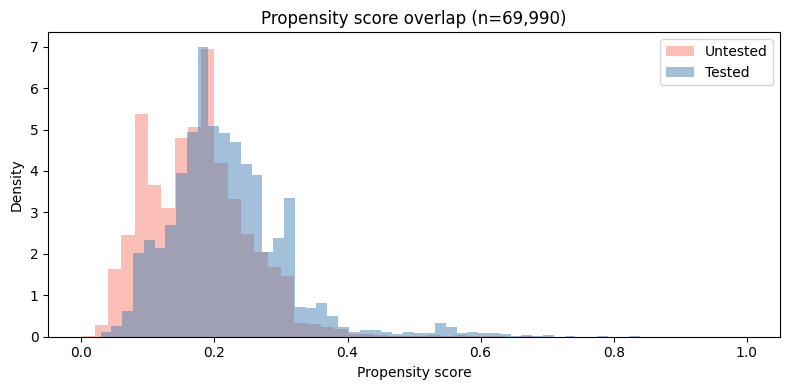

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(e_hat[A==0], bins=50, density=True, alpha=0.5, color='salmon', label='Untested')
ax.hist(e_hat[A==1], bins=50, density=True, alpha=0.5, color='steelblue', label='Tested')
ax.set_xlabel('Propensity score'); ax.set_ylabel('Density')
ax.set_title('Propensity score overlap (n=69,990)')
ax.legend(); plt.tight_layout()
plt.savefig('ps_overlap_v2.png', dpi=150)
plt.show()

## 11. Heterogeneity: outer cross-fitting

A separate causal forest is fitted per outer fold on training patients only and
used to predict effects for held-out patients. No patient contributes to the model
that predicts their own effect.

Takes roughly 10-15 minutes.

In [17]:
# Version verified for this notebook; the full environment is in requirements.txt.
%pip install -q econml==0.16.0


/home/claude/venv_final/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [18]:
from econml.dml import CausalForestDML

tau_oof = np.zeros(len(d))
outer = GroupKFold(n_splits=5)

for k, (tr, te) in enumerate(outer.split(Xv, A, groups=groups)):
    cf = CausalForestDML(
        model_y=GradientBoostingRegressor(n_estimators=150, max_depth=3,
                    learning_rate=0.05, random_state=SEED),
        model_t=GradientBoostingClassifier(n_estimators=150, max_depth=3,
                    learning_rate=0.05, random_state=SEED),
        discrete_treatment=True, n_estimators=500, min_samples_leaf=50,
        cv=GroupKFold(n_splits=3), random_state=SEED)
    cf.fit(Y[tr], A[tr], X=Xv[tr], groups=groups[tr])
    tau_oof[te] = cf.effect(Xv[te])
    print("fold", k+1, "done")

print("\nout-of-fold CATE SD:", round(tau_oof.std()*100, 3), "pp")

fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done

out-of-fold CATE SD: 2.499 pp


### Held-out ranking by predicted-benefit quintile

In [19]:
qh = pd.qcut(tau_oof, 5, labels=['Q1','Q2','Q3','Q4','Q5'])
rows = []
for g in ['Q1','Q2','Q3','Q4','Q5']:
    m = np.asarray(qh == g)
    p = psi[m]
    est = p.mean(); s = p.std(ddof=1)/np.sqrt(m.sum())
    rows.append([g, int(m.sum()), int(Y[m].sum()), round(est*100,3),
                 round((est-1.96*s)*100,3), round((est+1.96*s)*100,3),
                 round(tau_oof[m].mean()*100,3)])

qt = pd.DataFrame(rows, columns=['Group','N','Events','DR (pp)','CI low','CI high','Mean pred CATE'])
qt.to_csv('cate_quintiles_oof.csv', index=False)
print(qt.to_string(index=False))

sp = qt['DR (pp)'].max() - qt['DR (pp)'].min()
print("\nrealized spread :", round(sp,3), "pp")
print("predicted spread:", round(qt['Mean pred CATE'].max()-qt['Mean pred CATE'].min(),3), "pp")
print("rank correlation:", round(np.corrcoef(range(5), qt['DR (pp)'])[0,1], 3))

Group     N  Events  DR (pp)  CI low  CI high  Mean pred CATE
   Q1 14012    1423    0.096  -1.440    1.632          -3.476
   Q2 14000    1261   -1.216  -2.516    0.084          -1.493
   Q3 13984    1210   -0.718  -2.134    0.697          -0.302
   Q4 14050    1177    0.204  -1.046    1.453           1.122
   Q5 13944    1214    1.228  -0.119    2.576           3.404

realized spread : 2.444 pp
predicted spread: 6.88 pp
rank correlation: 0.621


### Top-versus-bottom quintile contrast

In [20]:
m1 = np.asarray(qh == 'Q1'); m5 = np.asarray(qh == 'Q5')
p1, p5 = psi[m1], psi[m5]
diff = p1.mean() - p5.mean()
se_d = np.sqrt(p1.var(ddof=1)/m1.sum() + p5.var(ddof=1)/m5.sum())
print(f"Q1 - Q5 contrast: {diff*100:.3f} pp")
print(f"95% CI: {(diff-1.96*se_d)*100:.3f} to {(diff+1.96*se_d)*100:.3f}")
print(f"p = {2*(1-stats.norm.cdf(abs(diff/se_d))):.4f}")

Q1 - Q5 contrast: -1.132 pp
95% CI: -3.176 to 0.911
p = 0.2774


### Held-out calibration

In [21]:
import statsmodels.api as sm

# Calibration regression of the DR scores on the out-of-fold CATEs.
# The reported interval uses heteroskedasticity-robust (HC3) standard errors, because the
# variance of the DR scores differs across patients. The classical OLS interval is printed
# for comparison only (it was the interval reported in manuscript v11).
cal_ols = sm.OLS(psi, sm.add_constant(tau_oof)).fit()
cal = sm.OLS(psi, sm.add_constant(tau_oof)).fit(cov_type='HC3')
slope, se_s = cal.params[1], cal.bse[1]
lo, hi = slope - 1.96*se_s, slope + 1.96*se_s
lo_ols = cal_ols.params[1] - 1.96*cal_ols.bse[1]; hi_ols = cal_ols.params[1] + 1.96*cal_ols.bse[1]

print(f"calibration slope: {slope:.4f}")
print(f"HC3 robust SE {se_s:.4f}   95% CI: {lo:.4f} to {hi:.4f}   (reported)")
print(f"classical SE  {cal_ols.bse[1]:.4f}   95% CI: {lo_ols:.4f} to {hi_ols:.4f}   (v11, for comparison)")
z0 = slope/se_s
print(f"H0 slope = 0 : p = {2*(1-stats.norm.cdf(abs(z0))):.6f}   (0 means no signal; HC3)")
t1 = (slope - 1)/se_s
print(f"H0 slope = 1 : p = {2*(1-stats.norm.cdf(abs(t1))):.6f}   (1 means well calibrated; HC3)")


calibration slope: 0.2139
HC3 robust SE 0.1448   95% CI: -0.0699 to 0.4976   (reported)
classical SE  0.1254   95% CI: -0.0319 to 0.4596   (v11, for comparison)
H0 slope = 0 : p = 0.139630   (0 means no signal; HC3)
H0 slope = 1 : p = 0.000000   (1 means well calibrated; HC3)


### RATE / AUTOC

In [22]:
# TOC curve computed by hand: econml has no native RATE implementation.
# Priority scores are out-of-fold CATEs; evaluation scores are the cross-fitted
# doubly robust scores psi. No patient's own outcome informs their own ranking.
order = np.argsort(tau_oof)           # ascending: strongest predicted benefit first
psi_sorted = psi[order]
n = len(psi_sorted)
overall = psi.mean()

qgrid = np.arange(1, n+1)/n
cum = np.cumsum(psi_sorted)/np.arange(1, n+1)
toc = cum - overall
autoc = trapz(toc, qgrid)

# bootstrap over patients, forest held fixed
rng = np.random.default_rng(SEED)
boots = []
for _ in range(200):
    idx = rng.integers(0, n, n)
    ps_b = psi[idx]; ta_b = tau_oof[idx]
    o = np.argsort(ta_b)
    cb = np.cumsum(ps_b[o])/np.arange(1, n+1)
    boots.append(trapz(cb - ps_b.mean(), qgrid))
se_a = np.std(boots, ddof=1)

print(f"AUTOC: {autoc*100:.4f} pp   SE {se_a*100:.4f}")
print(f"95% CI: {(autoc-1.96*se_a)*100:.4f} to {(autoc+1.96*se_a)*100:.4f}")
print(f"p = {2*(1-stats.norm.cdf(abs(autoc/se_a))):.4f}")


AUTOC: -0.1042 pp   SE 0.4591
95% CI: -1.0040 to 0.7956
p = 0.8204


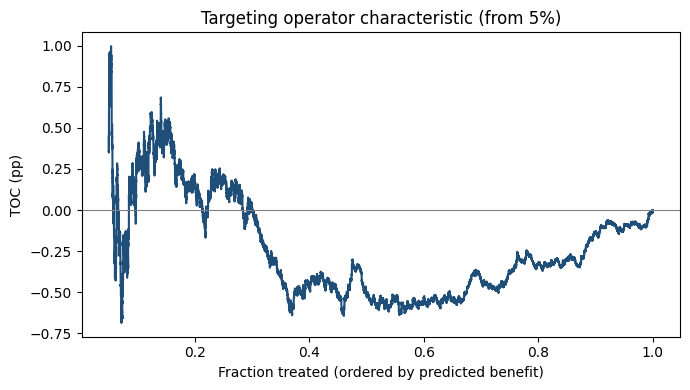

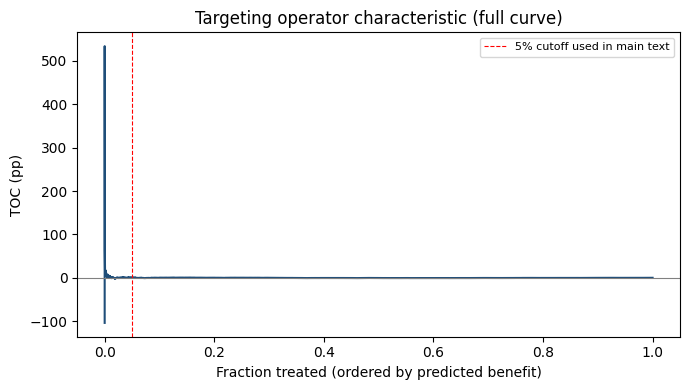

In [23]:
# Main-text figure: TOC from a 5% minimum fraction. This is a display restriction
# for numerical and visual stability, not a prespecified choice: below 5% the
# cumulative mean is computed on very few patients and is unstable. The restriction
# is stated in the figure caption and the full curve is kept as Appendix Figure A2.
QMIN = 0.05
m = qgrid >= QMIN

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(qgrid[m], toc[m]*100, color='#1f4e79')
ax.axhline(0, color='grey', lw=0.8)
ax.set_xlabel('Fraction treated (ordered by predicted benefit)')
ax.set_ylabel('TOC (pp)')
ax.set_title(f'Targeting operator characteristic (from {QMIN:.0%})')
fig.tight_layout(); fig.savefig('toc_curve.png', dpi=150); plt.show()

# Supplementary figure: full curve including the unstable left tail.
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(qgrid, toc*100, color='#1f4e79')
ax.axvline(QMIN, color='red', ls='--', lw=0.8, label='5% cutoff used in main text')
ax.axhline(0, color='grey', lw=0.8)
ax.set_xlabel('Fraction treated (ordered by predicted benefit)')
ax.set_ylabel('TOC (pp)')
ax.set_title('Targeting operator characteristic (full curve)')
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig('toc_curve_full.png', dpi=150); plt.show()


In [24]:
cal_out = pd.DataFrame([
    ['Calibration slope (HC3 CI)', round(slope,4), round(lo,4), round(hi,4)],
    ['AUTOC (pp)', round(autoc*100,4),
     round((autoc-1.96*se_a)*100,4), round((autoc+1.96*se_a)*100,4)],
    ['Q1 - Q5 contrast (pp)', round(diff*100,3),
     round((diff-1.96*se_d)*100,3), round((diff+1.96*se_d)*100,3)],
], columns=['Quantity','Estimate','CI low','CI high'])
cal_out.to_csv('heterogeneity_summary.csv', index=False)
print(cal_out.to_string(index=False))

                  Quantity  Estimate  CI low  CI high
Calibration slope (HC3 CI)    0.2139 -0.0699   0.4976
                AUTOC (pp)   -0.1042 -1.0040   0.7956
     Q1 - Q5 contrast (pp)   -1.1320 -3.1760   0.9110


## 12. Diagnosis-specific effects

Same cross-fitted doubly robust estimator, risk-difference scale.
The 10 patients with a Missing diagnosis group are excluded.

In [25]:
GROUPS = sorted([x for x in d['diag_group'].unique() if x != 'Missing'])

rows = []
for g in GROUPS:
    m = (d['diag_group'] == g).values
    p = psi[m]
    est = p.mean(); s = p.std(ddof=1)/np.sqrt(m.sum())
    ww = w_stab[m]
    ess = ww.sum()**2/(ww**2).sum()
    rows.append([g, int(m.sum()), int(Y[m].sum()), round(ess,1),
                 round(est*100,3), round((est-1.96*s)*100,3), round((est+1.96*s)*100,3)])

sub = pd.DataFrame(rows, columns=['Diagnosis','N','Events','ESS','DR (pp)','CI low','CI high'])
sub = sub.sort_values('DR (pp)').reset_index(drop=True)

from statsmodels.stats.multitest import multipletests
se_sub = (sub['CI high'] - sub['CI low'])/(2*1.96)
z = sub['DR (pp)']/se_sub
pv = 2*(1 - stats.norm.cdf(abs(z)))
sub['p'] = pv.round(4)
sub['p_BH'] = multipletests(pv, method='fdr_bh')[1].round(4)

sub.to_csv('diagnosis_subgroups_v2.csv', index=False)
print(sub.to_string(index=False))

      Diagnosis     N  Events     ESS  DR (pp)  CI low  CI high      p   p_BH
         Injury  4696     507  4510.5   -3.715  -5.628   -1.802 0.0001 0.0013
    Respiratory  9491     693  9097.3   -1.745  -3.264   -0.226 0.0243 0.1096
       Diabetes  5748     524  5118.5   -0.584  -3.324    2.156 0.6761 0.9249
          Other 12124    1089 11596.2   -0.146  -1.538    1.247 0.8372 0.9249
      Neoplasms  2538     230  2403.2   -0.133  -2.897    2.632 0.9249 0.9249
Musculoskeletal  4064     341  3807.1    0.414  -2.040    2.868 0.7409 0.9249
      Digestive  6488     520  6240.6    0.742  -0.887    2.370 0.3718 0.6693
    Circulatory 21390    2070 20407.0    0.997  -0.223    2.217 0.1092 0.3276
  Genitourinary  3441     309  1206.1    1.645  -1.009    4.300 0.2245 0.5052


In [26]:
# Joint Wald test of equality of the nine diagnosis-group effects.
# theta_g is the mean DR score in group g (unrounded). Groups contain disjoint patients,
# so the influence functions 1{G=g}(psi - theta_g)/P(G=g) are orthogonal across groups and
# the covariance matrix of the estimates is diagonal, with entries var(psi_g)/n_g.
# H0: theta_1 = ... = theta_9, tested with 8 contrasts (group 1 minus each other group).
# (v4 centred each group on the overall mean DR score instead; that statistic is not a
# test of equality and is not chi-square with 8 df, so it was replaced.)
theta = np.array([psi[(d['diag_group'] == g).values].mean() for g in GROUPS])
V = np.diag([psi[(d['diag_group'] == g).values].var(ddof=1) / (d['diag_group'] == g).sum()
             for g in GROUPS])
Cm = np.hstack([np.ones((len(GROUPS)-1, 1)), -np.eye(len(GROUPS)-1)])
cdiff = Cm @ theta
wald = float(cdiff @ np.linalg.solve(Cm @ V @ Cm.T, cdiff))
dfree = len(GROUPS) - 1
p_wald = stats.chi2.sf(wald, dfree)
print("Joint Wald test of equality across diagnosis groups")
print(f"chi2 = {wald:.3f}   df = {dfree}   p = {p_wald:.5f}")

# For comparison only: the v4 statistic (each group centred on the overall mean DR score).
gm = psi.mean()
v4_stat = sum((psi[(d['diag_group'] == g).values].mean() - gm)**2
              / (psi[(d['diag_group'] == g).values].var(ddof=1) / (d['diag_group'] == g).sum()) for g in GROUPS)
print(f"(v4 calculation, not a valid test: {v4_stat:.3f})")


Joint Wald test of equality across diagnosis groups
chi2 = 24.091   df = 8   p = 0.00221


(v4 calculation, not a valid test: 24.373)


## 13. Sensitivity analyses

S1–S3 examine cohort construction and propensity-score overlap. No dated record shows
that S1–S3 were specified before their results were examined. S4 (adjusting for diagnosis
group) was added after the covariate-timing review.


In [27]:
def run_aipw(dd, Xd, seed=SEED):
    Av = dd['A'].values; Yv = dd['Y'].values; gv = dd['patient_nbr'].values
    Xa = Xd.values
    eh = np.zeros(len(dd)); m0 = np.zeros(len(dd)); m1 = np.zeros(len(dd))
    for tr, te in GroupKFold(n_splits=5).split(Xa, Av, groups=gv):
        ps = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
        ps.fit(Xa[tr], Av[tr]); eh[te] = ps.predict_proba(Xa[te])[:,1]
        for av, mu in [(0,m0),(1,m1)]:
            mm = tr[Av[tr]==av]
            gb = GradientBoostingClassifier(n_estimators=200, max_depth=3,
                    learning_rate=0.05, subsample=0.8, random_state=seed)
            gb.fit(Xa[mm], Yv[mm]); mu[te] = gb.predict_proba(Xa[te])[:,1]
    ec = np.clip(eh, EPS, 1-EPS)
    ps_i = (m1-m0) + Av*(Yv-m1)/ec - (1-Av)*(Yv-m0)/(1-ec)
    e = ps_i.mean(); s = ps_i.std(ddof=1)/np.sqrt(len(ps_i))
    return e*100, (e-1.96*s)*100, (e+1.96*s)*100

sens = [['Primary (Order A, clip 0.01)', round(aipw*100,3), round(ci_lo*100,3), round(ci_hi*100,3)]]
print("primary done")

primary done


In [28]:
# S1: alternative cohort ordering rule (Order B)
db = (df.sort_values('encounter_id')
        .drop_duplicates('patient_nbr', keep='first')
        .loc[lambda t: ~t['discharge_disposition_id'].isin(BAD)]
        .reset_index(drop=True))
db['A'] = db['A1Cresult'].isin(TESTED).astype(int)
db['Y'] = (db['readmitted']=='<30').astype(int)
db['diag_group'] = db['diag_1'].apply(dxgroup)
Xb = pd.get_dummies(db[CAT].astype(str), drop_first=True)
Xb = pd.concat([Xb, db[NUM]], axis=1).astype(float).reindex(columns=X.columns, fill_value=0.0)
r = run_aipw(db, Xb)
sens.append(['S1: Order B cohort', round(r[0],3), round(r[1],3), round(r[2],3)])
print(sens[-1])

['S1: Order B cohort', np.float64(-0.087), np.float64(-0.71), np.float64(0.536)]


In [29]:
# S2: tighter clipping at 0.05 (overlap restriction)
ec2 = np.clip(e_hat, 0.05, 0.95)
psi2 = (mu1-mu0) + A*(Y-mu1)/ec2 - (1-A)*(Y-mu0)/(1-ec2)
e2 = psi2.mean(); s2 = psi2.std(ddof=1)/np.sqrt(len(psi2))
sens.append(['S2: clip at [0.05, 0.95]', round(e2*100,3),
             round((e2-1.96*s2)*100,3), round((e2+1.96*s2)*100,3)])

# S3: restrict to region of common support, no clipping
keep = (e_hat > 0.05) & (e_hat < 0.95)
psi3 = psi[keep]
e3 = psi3.mean(); s3 = psi3.std(ddof=1)/np.sqrt(len(psi3))
sens.append([f'S3: restricted to overlap (n={keep.sum()})', round(e3*100,3),
             round((e3-1.96*s3)*100,3), round((e3+1.96*s3)*100,3)])
print(sens[-1])


['S3: restricted to overlap (n=68891)', np.float64(-0.048), np.float64(-0.651), np.float64(0.555)]


In [30]:
# S4: previous specification, adjusting for diagnosis group.
# Retained as a sensitivity analysis after diag_group was removed from the
# primary set on covariate-timing grounds.
r4 = run_aipw(d, X_s4)
sens.append(['S4: adjusting for diagnosis group', round(r4[0],3), round(r4[1],3), round(r4[2],3)])
print(sens[-1])
sens_df = pd.DataFrame(sens, columns=['Analysis','RD (pp)','CI low','CI high'])
sens_df.to_csv('sensitivity_analyses.csv', index=False)
print(sens_df.to_string(index=False))


['S4: adjusting for diagnosis group', np.float64(-0.215), np.float64(-0.836), np.float64(0.406)]
                           Analysis  RD (pp)  CI low  CI high
       Primary (Order A, clip 0.01)   -0.082  -0.696    0.532
                 S1: Order B cohort   -0.087  -0.710    0.536
           S2: clip at [0.05, 0.95]   -0.080  -0.688    0.527
S3: restricted to overlap (n=68891)   -0.048  -0.651    0.555
  S4: adjusting for diagnosis group   -0.215  -0.836    0.406


## 14. Study timeline figure

In [31]:
import matplotlib.pyplot as plt

def panel(ax, title, t0_x, note):
    adm, dis, end = 0, 4, 10  # schematic positions, not to scale
    ax.axvspan(adm, dis, ymin=0.42, ymax=0.58, color='orange', alpha=0.35)
    ax.hlines(0, adm, end, color='black', lw=2)
    for x, lab in [(adm, 'Admission'), (dis, 'Discharge'), (end, '30 days\npost-discharge')]:
        ax.vlines(x, -0.12, 0.12, color='black')
        ax.text(x, -0.35, lab, ha='center', va='top', fontsize=10)
    ax.text(dis/2, 0.62, 'HbA1c measured? (yes/no recorded;\ntiming NOT recorded)', ha='center', fontsize=9, style='italic')
    ax.annotate('', xy=(end, 0.55), xytext=(dis, 0.55), arrowprops=dict(arrowstyle='<->', color='steelblue'))
    ax.text((dis+end)/2, 0.62, 'Outcome window: readmission within 30 days', ha='center', color='steelblue', fontsize=9)
    ax.plot(t0_x, 0.22, marker='v', color='crimson', ms=14, clip_on=False, zorder=5)
    ax.text(t0_x, 0.33, 'Time zero', ha='center', color='crimson', fontsize=10, weight='bold')
    ax.text(end/2, -1.0, note, ha='center', fontsize=9, color='dimgray')
    ax.set_title(title, loc='left', fontsize=11, weight='bold')
    ax.set_xlim(-1, 11); ax.set_ylim(-1.3, 1.2); ax.axis('off')

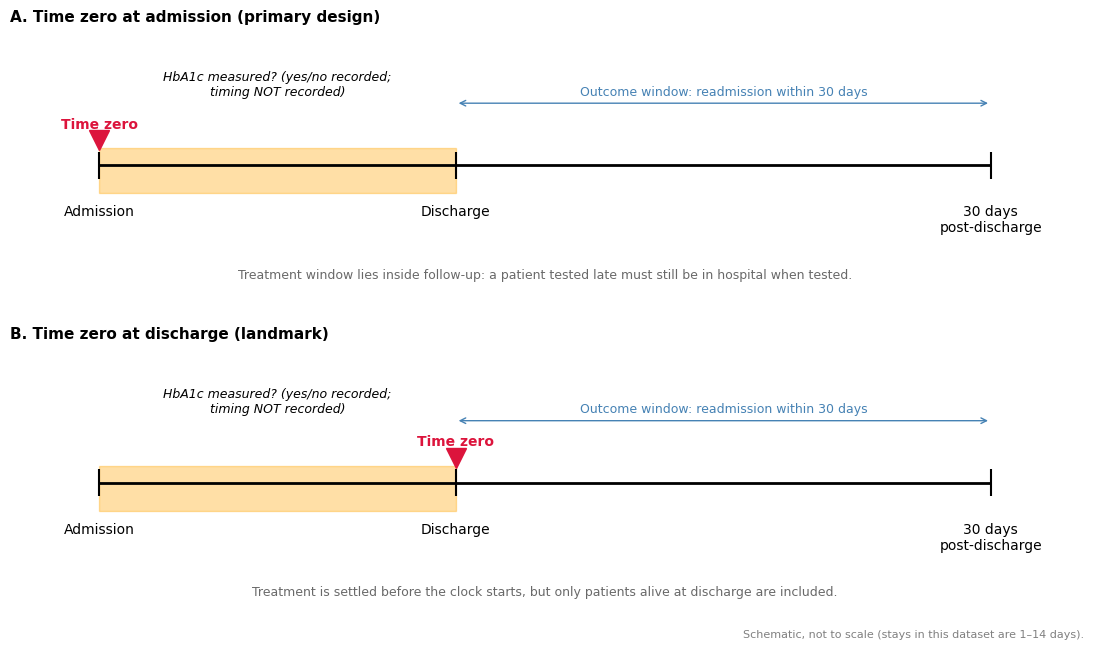

In [32]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
panel(axes[0], 'A. Time zero at admission (primary design)', 0,
      'Treatment window lies inside follow-up: a patient tested late must still be in hospital when tested.')
panel(axes[1], 'B. Time zero at discharge (landmark)', 4,
      'Treatment is settled before the clock starts, but only patients alive at discharge are included.')
fig.text(0.99, 0.01, 'Schematic, not to scale (stays in this dataset are 1–14 days).',
         ha='right', fontsize=8, color='gray')
plt.tight_layout()
plt.savefig('timeline_v2.png', dpi=200, bbox_inches='tight')
plt.show()

## 15. Output manifest

In [33]:
import os
outs = ['cohort_flow_v2.csv','covariate_timing_table_v2.csv','master_table.csv',
        'ate_estimates_v2.csv','weight_diagnostics.csv','ess_by_arm.csv',
        'balance_v2.csv','cate_quintiles_oof.csv','diagnosis_subgroups_v2.csv',
        'heterogeneity_summary.csv','sensitivity_analyses.csv','ps_overlap_v2.png',
        'toc_curve.png','toc_curve_full.png','timeline_v2.png']
for f in outs:
    print(f"{'OK ' if os.path.exists(f) else 'MISSING':8s} {f}")

OK       cohort_flow_v2.csv
OK       covariate_timing_table_v2.csv
OK       master_table.csv
OK       ate_estimates_v2.csv
OK       weight_diagnostics.csv
OK       ess_by_arm.csv
OK       balance_v2.csv
OK       cate_quintiles_oof.csv
OK       diagnosis_subgroups_v2.csv
OK       heterogeneity_summary.csv
OK       sensitivity_analyses.csv
OK       ps_overlap_v2.png
OK       toc_curve.png
OK       toc_curve_full.png
OK       timeline_v2.png


In [34]:
import pandas as pd
for f in ['master_table.csv','ate_estimates_v2.csv','cate_quintiles_oof.csv',
          'sensitivity_analyses.csv','diagnosis_subgroups_v2.csv']:
    print('='*60)
    print(f)
    print(pd.read_csv(f).to_string(index=False))

master_table.csv
                           Quantity    Tested (A=1)  Untested (A=0)
                                  N           12846       57144.000
                     Outcome events            1079        5206.000
         Unadjusted 30-day risk (%)             8.4           9.110
Outcome-model standardized risk (%)           8.884           9.018
             AIPW marginal risk (%)           8.895           8.977
  AIPW marginal risk 95% CI low (%)           8.327           8.740
 AIPW marginal risk 95% CI high (%)           9.462           9.214
          AIPW risk difference (pp)          -0.082             NaN
                AIPW RD 95% CI (pp) -0.696 to 0.532             NaN
ate_estimates_v2.csv
         Estimator  RD_pp  CI_low  CI_high
             Crude -0.711     NaN      NaN
Outcome regression -0.134     NaN      NaN
  IPW (stabilized)  0.013     NaN      NaN
              AIPW -0.082  -0.696    0.532
cate_quintiles_oof.csv
Group     N  Events  DR (pp)  CI low  CI hig

## 16. Environment

Python and package versions from this run (copied into `requirements.txt`).


In [35]:
import sys, sklearn, scipy, statsmodels, matplotlib, econml
print("python", sys.version.split()[0])
for mod in (np, pd, scipy, sklearn, statsmodels, matplotlib, econml):
    name = {'np': 'numpy', 'pd': 'pandas', 'sklearn': 'scikit-learn'}.get(mod.__name__, mod.__name__)
    print(f"{name}=={mod.__version__}")


python 3.12.3
numpy==2.3.5
pandas==2.2.2
scipy==1.16.3
scikit-learn==1.6.1
statsmodels==0.14.5
matplotlib==3.10.7
econml==0.16.0


In [36]:
!zip -r results.zip *.csv *.png -x diabetic_data.csv
print("done")

  adding: ate_estimates_v2.csv (deflated 10%)
  adding: balance_v2.csv (deflated 63%)
  adding: cate_quintiles_oof.csv (deflated 28%)
  adding: cohort_flow_v2.csv (deflated 17%)
  adding: covariate_timing_table_v2.csv (deflated 68%)
  adding: diagnosis_subgroups_v2.csv (deflated 37%)
  adding: ess_by_arm.csv (deflated 45%)
  adding: heterogeneity_summary.csv (deflated 13%)
  adding: master_table.csv (deflated 38%)
  adding: sensitivity_analyses.csv (deflated 26%)
  adding: weight_diagnostics.csv (deflated 39%)
  adding: ps_overlap_v2.png (deflated 20%)
  adding: timeline_v2.png (deflated 17%)
  adding: toc_curve.png (deflated 7%)
  adding: toc_curve_full.png (deflated 15%)


done
